# Análise Exploratória de Dados (EDA) - ENEM 2023
## Diagnóstico do Alvo (`NU_NOTA_MT`) e Categorias Raras

Este notebook tem como finalidade investigar a base de desenvolvimento higienizada (`dados/processed/desenvolvimento_higienizado.csv`), atendendo a duas investigações centrais:

1. **Distribuição da Variável Alvo (`NU_NOTA_MT`):** Compreender a dispersão contínua da nota de Matemática, com ênfase especial na concentração e impacto de candidatos com notas exatamente iguais a zero.
2. **Detecção de Categorias Raras (*Rare Labels*):** Identificar categorias com representatividade reduzida nas principais variáveis sociodemográficas para prevenir instabilidade numérica e sobreajuste em modelos preditivos futuros.

> **Regra de Integridade:** Nenhuma linha, outlier ou nota zero é removida. Todos os valores extremos são preservados como parte legítima da população avaliada.

### 📖 Dicionário de Códigos e Legenda Oficial (Inep - ENEM 2023)

Abaixo está a referência oficial dos valores categóricos para interpretar os gráficos:

#### 💍 `TP_ESTADO_CIVIL` (Estado Civil)
| Código | Significado Oficial |
| :---: | :--- |
| `0` | Não informado |
| `1` | Solteiro(a) |
| `2` | Casado(a) / Mora com companheiro(a) |
| `3` | Divorciado(a) / Desquitado(a) / Separado(a) |
| `4` | Viúvo(a) |

---

#### 👤 `TP_COR_RACA` (Cor ou Raça Autodeclarada)
| Código | Significado Oficial |
| :---: | :--- |
| `0` | Não declarado |
| `1` | Branca |
| `2` | Preta |
| `3` | Parda |
| `4` | Amarela |
| `5` | Indígena |
| `6` | Não dispõe da informação |

---

#### 🏫 `TP_ESCOLA` (Tipo de Escola do Ensino Médio)
| Código | Significado Oficial |
| :---: | :--- |
| `1` | Não respondeu (egressos de anos anteriores ou não informado) |
| `2` | Pública |
| `3` | Privada |

---

#### 💰 `Q006` (Renda Familiar Mensal - Salário Mínimo de 2023: R$ 1.320,00)
| Faixa | Intervalo de Renda |
| :---: | :--- |
| `A` | Nenhuma Renda |
| `B` | Até R$ 1.320,00 (Até 1 SM) |
| `C` | De R$ 1.320,01 até R$ 1.980,00 (1 a 1,5 SM) |
| `D` | De R$ 1.980,01 até R$ 2.640,00 (1,5 a 2 SM) |
| `E` | De R$ 2.640,01 até R$ 3.300,00 (2 a 2,5 SM) |
| `F` | De R$ 3.300,01 até R$ 3.960,00 (2,5 a 3 SM) |
| `G` | De R$ 3.960,01 até R$ 5.280,00 (3 a 4 SM) |
| `H` | De R$ 5.280,01 até R$ 6.600,00 (4 a 5 SM) |
| `I` | De R$ 6.600,01 até R$ 7.920,00 (5 a 6 SM) |
| `J` | De R$ 7.920,01 até R$ 9.240,00 (6 a 7 SM) |
| `K` | De R$ 9.240,01 até R$ 10.560,00 (7 a 8 SM) |
| `L` | De R$ 10.560,01 até R$ 11.880,00 (8 a 9 SM) |
| `M` | De R$ 11.880,01 até R$ 13.200,00 (9 a 10 SM) |
| `N` | De R$ 13.200,01 até R$ 15.840,00 (10 a 12 SM) |
| `O` | De R$ 15.840,01 até R$ 19.800,00 (12 a 15 SM) |
| `P` | De R$ 19.800,01 até R$ 26.400,00 (15 a 20 SM) |
| `Q` | Mais de R$ 26.400,00 (Mais de 20 SM) |
| `Nao_Informado` | Resposta em branco (tratada com valor constante na higienização) |

---

#### 📋 Demais Variáveis Demográficas e Escolares
| Variável | Valores e Descrição |
| :--- | :--- |
| `TP_SEXO` | `M` = Masculino \| `F` = Feminino |
| `TP_LINGUA` | `0` = Inglês \| `1` = Espanhol |
| `TP_ST_CONCLUSAO` | `1` = Concluído \| `2` = Concluindo em 2023 \| `3` = Cursando (conclusão pós-2023) \| `4` = Não concluído/não cursando |
| `TP_ENSINO` | `0` = Não se aplica (concluiu em anos anteriores) \| `1` = Ensino Regular \| `2` = Educação Especial |
| `IN_TREINEIRO` | `0` = Não treineiro \| `1` = Treineiro (participa para autoavaliação) |


### 1. Setup do Ambiente e Configurações Visuais
Importação dos pacotes de análise e visualização (`pandas`, `matplotlib`, `seaborn`) e definição do diretório de destino das figuras em `../resultados/figuras/`.

In [7]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração estética global
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'figure.titlesize': 14,
    'figure.dpi': 150
})

# Diretório para exportação de figuras conforme especificado
output_dir = Path("../resultados/figuras")
output_dir.mkdir(parents=True, exist_ok=True)

print(f"Diretório de saída das figuras configurado: {output_dir.resolve()}")

Diretório de saída das figuras configurado: C:\Users\alyra\Documents\Faculdade\Ciência de Dados\ciencia-de-dados-unifor-projeto-2\resultados\figuras


### 2. Carregamento dos Dados Higienizados
Leitura da partição de desenvolvimento higienizada a partir de `../dados/processed/desenvolvimento_higienizado.csv`.

In [8]:
caminho_dados = Path("../dados/processed/desenvolvimento_higienizado.csv")
if not caminho_dados.exists():
    caminho_dados = Path("dados/processed/desenvolvimento_higienizado.csv")

print(f"Carregando dados de: {caminho_dados.resolve()}...")
df = pd.read_csv(caminho_dados)

print(f"Base carregada com sucesso!")
print(f"Total de linhas (desenvolvimento): {df.shape[0]:,}")
print(f"Total de colunas: {df.shape[1]}")
display(df.head(3))

Carregando dados de: C:\Users\alyra\Documents\Faculdade\Ciência de Dados\ciencia-de-dados-unifor-projeto-2\dados\processed\desenvolvimento_higienizado.csv...
Base carregada com sucesso!
Total de linhas (desenvolvimento): 2,153,941
Total de colunas: 39


,NU_INSCRICAO,TP_FAIXA_ETARIA,TP_SEXO,TP_ESTADO_CIVIL,TP_COR_RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,TP_ANO_CONCLUIU,TP_ESCOLA,TP_ENSINO,...,Q016,Q017,Q018,Q019,Q020,Q021,Q022,Q023,Q024,Q025
0,210061103945,6,F,1,1,1,1,0,1,0,...,B,A,A,B,A,A,A,A,A,B
1,210059980948,3,F,1,3,1,2,0,2,1,...,A,A,A,B,A,A,B,A,A,A
2,210060801601,11,M,1,1,1,1,8,1,0,...,B,A,B,C,B,A,C,A,B,B


### 3. Análise da Variável Alvo (`NU_NOTA_MT`)
Investigamos a distribuição da nota contínua de Matemática.

No ENEM, notas **iguais a zero** na prova objetiva de Matemática demandam atenção específica: elas indicam participantes que erraram todos os itens respondidos ou preencheram a folha de respostas em branco. O gráfico abaixo destaca essa concentração atípica em contraste com a distribuição contínua da Teoria de Resposta ao Item (TRI).

> O gráfico gerado é salvo em `../resultados/figuras/distribuicao_alvo.png`.

DIAGNÓSTICO DA VARIÁVEL ALVO (NU_NOTA_MT)
Média: 533.83 | Mediana: 523.50 | Desvio-Padrão: 131.63
Mínimo: 0.00 | Máximo: 958.60
Total de candidatos com nota EXATAMENTE zero: 13,300 (0.617%)
Gráfico salvo: C:\Users\alyra\Documents\Faculdade\Ciência de Dados\ciencia-de-dados-unifor-projeto-2\resultados\figuras\distribuicao_alvo.png


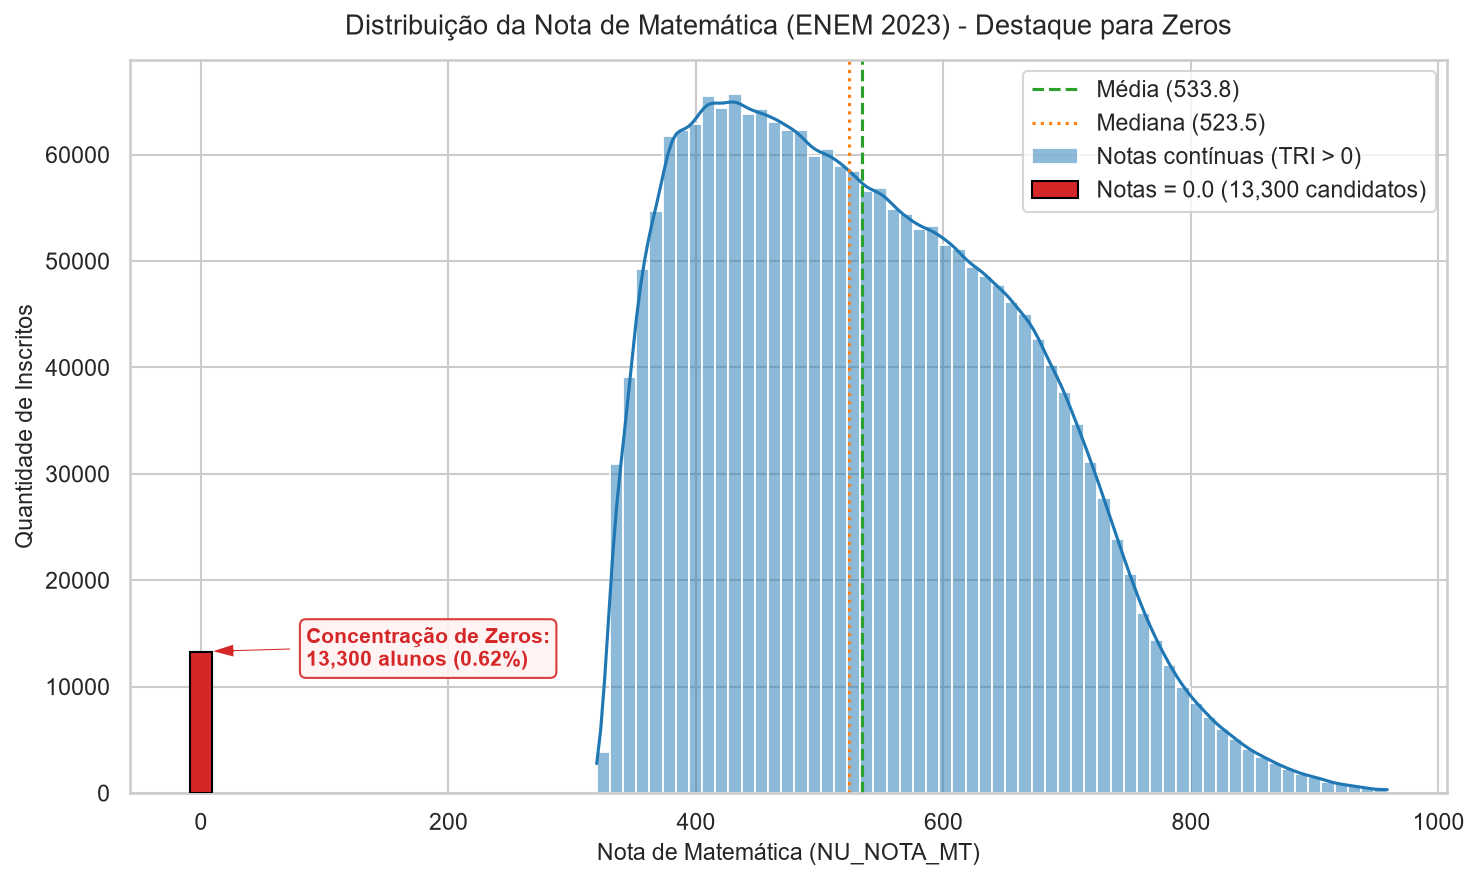

In [9]:
alvo = 'NU_NOTA_MT'

# Métricas descritivas básicas
media_alvo = df[alvo].mean()
mediana_alvo = df[alvo].median()
desvio_alvo = df[alvo].std()
qtd_zeros = (df[alvo] == 0).sum()
pct_zeros = (qtd_zeros / len(df)) * 100

print("=" * 60)
print(f"DIAGNÓSTICO DA VARIÁVEL ALVO ({alvo})")
print("=" * 60)
print(f"Média: {media_alvo:.2f} | Mediana: {mediana_alvo:.2f} | Desvio-Padrão: {desvio_alvo:.2f}")
print(f"Mínimo: {df[alvo].min():.2f} | Máximo: {df[alvo].max():.2f}")
print(f"Total de candidatos com nota EXATAMENTE zero: {qtd_zeros:,} ({pct_zeros:.3f}%)")
print("=" * 60)

# Plotagem da distribuição com destaque para notas zero
fig, ax = plt.subplots(figsize=(10, 6))

# Histograma da distribuição contínua (notas > 0)
sns.histplot(
    data=df[df[alvo] > 0],
    x=alvo,
    bins=60,
    color="#1f77b4",
    kde=True,
    stat="count",
    ax=ax,
    label="Notas contínuas (TRI > 0)"
)

# Barra destacada para os participantes com nota exatamente zero
if qtd_zeros > 0:
    ax.bar(
        x=0,
        height=qtd_zeros,
        width=18,
        color="#d62728",
        edgecolor="black",
        label=f"Notas = 0.0 ({qtd_zeros:,} candidatos)",
        zorder=5
    )
    
    # Anotação com seta indicativa
    ax.annotate(
        f"Concentração de Zeros:\n{qtd_zeros:,} alunos ({pct_zeros:.2f}%)",
        xy=(0, qtd_zeros),
        xytext=(85, qtd_zeros * 0.9 if qtd_zeros > 1000 else qtd_zeros + 8000),
        arrowprops=dict(facecolor="#d62728", shrink=0.08, width=1.5, headwidth=7),
        fontsize=10,
        fontweight="bold",
        color="#d62728",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#fff2f2", edgecolor="#d62728", alpha=0.9)
    )

ax.axvline(media_alvo, color="#2ca02c", linestyle="--", linewidth=1.5, label=f"Média ({media_alvo:.1f})")
ax.axvline(mediana_alvo, color="#ff7f0e", linestyle=":", linewidth=1.5, label=f"Mediana ({mediana_alvo:.1f})")

ax.set_title("Distribuição da Nota de Matemática (ENEM 2023) - Destaque para Zeros", fontsize=13, pad=12)
ax.set_xlabel("Nota de Matemática (NU_NOTA_MT)", fontsize=11)
ax.set_ylabel("Quantidade de Inscritos", fontsize=11)
ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
fig_alvo_path = output_dir / "distribuicao_alvo.png"
plt.savefig(fig_alvo_path, dpi=300)
print(f"Gráfico salvo: {fig_alvo_path.resolve()}")
plt.show()

### 4. Análise de Categorias Raras (*Rare Labels*)
Nesta seção, inspecionamos as distribuições de frequência das principais variáveis sociodemográficas e econômicas:

* `Q006`: Renda familiar mensal dividida em 17 faixas (`A` a `Q`), onde as classes extremas (`P`, `Q` ou `A`) frequentemente possuem baixa densidade amostral.
* `TP_COR_RACA`: Autodeclaração étnico-racial, identificando grupos com volumes diminutos (ex.: `5 = Indígena`, `0 = Não declarado`).
* `TP_ESCOLA`: Tipo de escola no Ensino Médio (`1 = Não respondeu`, `2 = Pública`, `3 = Privada`).
* `TP_ESTADO_CIVIL`: Estado civil do candidato (`0 = Não informado`, `3 = Divorciado`, `4 = Viúvo`).

O objetivo é mapear visualmente e numericamente categorias com **representatividade inferior a 1,5%**, que exigirão atenção na etapa de engenharia de atributos (como agrupamento em 'Outros' para evitar esparsidade).

> O painel com os gráficos é salvo em `../resultados/figuras/analise_categorias.png`.

Gráfico salvo: C:\Users\alyra\Documents\Faculdade\Ciência de Dados\ciencia-de-dados-unifor-projeto-2\resultados\figuras\analise_categorias.png


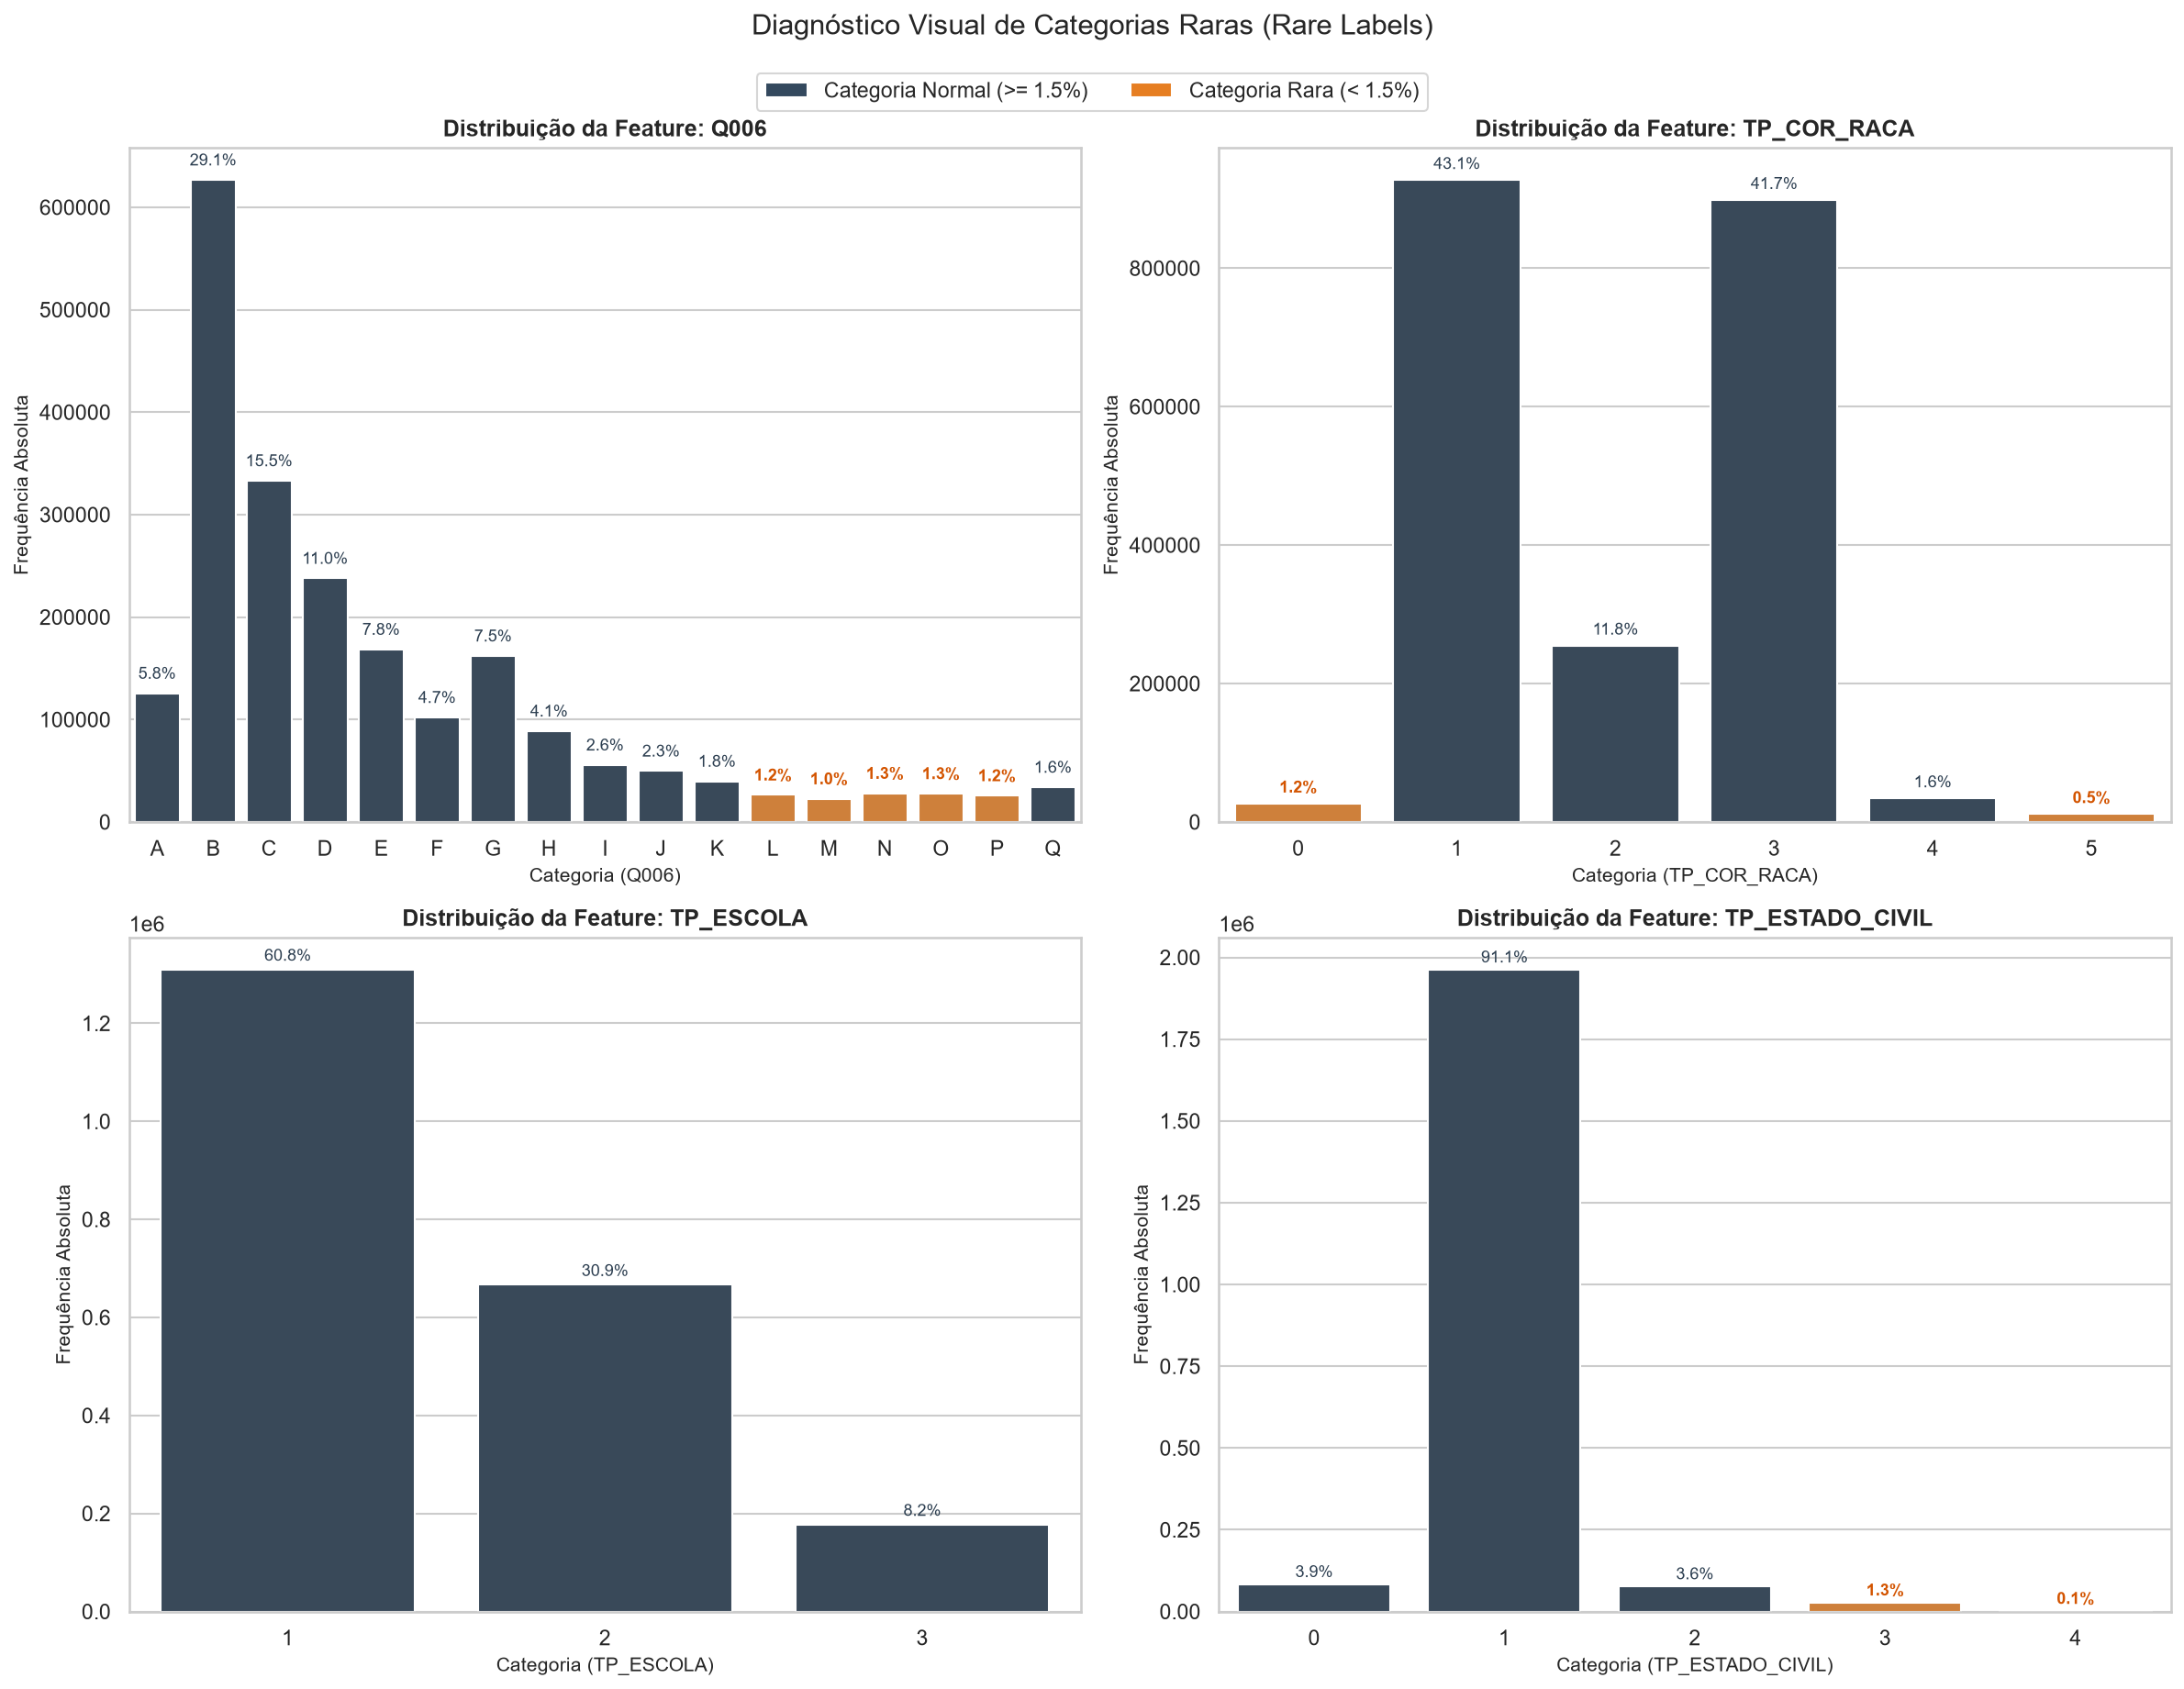

In [10]:
features_para_analise = ['Q006', 'TP_COR_RACA', 'TP_ESCOLA', 'TP_ESTADO_CIVIL']
limiar_raridade_pct = 1.5

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, col in enumerate(features_para_analise):
    ax = axes[idx]
    
    # Contagem de ocorrências e percentual relativo
    contagens = df[col].astype(str).value_counts().sort_index()
    total_amostras = len(df)
    percentuais = (contagens / total_amostras) * 100
    
    # Identificação visual de categorias raras (< 1.5%)
    paleta = ['#e67e22' if pct < limiar_raridade_pct else '#34495e' for pct in percentuais]
    
    sns.barplot(
        x=contagens.index,
        y=contagens.values,
        hue=contagens.index,
        palette=paleta,
        legend=False,
        ax=ax
    )
    
    ax.set_title(f"Distribuição da Feature: {col}", fontsize=12, fontweight="bold")
    ax.set_xlabel(f"Categoria ({col})", fontsize=10)
    ax.set_ylabel("Frequência Absoluta", fontsize=10)
    
    # Adicionar anotação percentual acima de cada barra
    for bar, pct in zip(ax.patches, percentuais):
        altura = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            altura + (total_amostras * 0.005),
            f"{pct:.1f}%",
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold" if pct < limiar_raridade_pct else "normal",
            color="#d35400" if pct < limiar_raridade_pct else "#2c3e50"
        )

# Legenda explicativa do diagnóstico
from matplotlib.patches import Patch
legenda_elementos = [
    Patch(facecolor="#34495e", label=f"Categoria Normal (>= {limiar_raridade_pct}%)"),
    Patch(facecolor="#e67e22", label=f"Categoria Rara (< {limiar_raridade_pct}%)")
]
fig.legend(handles=legenda_elementos, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.99), fontsize=11)

plt.suptitle("Diagnóstico Visual de Categorias Raras (Rare Labels)", fontsize=15, y=1.02)
plt.tight_layout()

fig_cat_path = output_dir / "analise_categorias.png"
plt.savefig(fig_cat_path, dpi=300, bbox_inches="tight")
print(f"Gráfico salvo: {fig_cat_path.resolve()}")
plt.show()

### 5. Tabela Sintética de Categorias Raras Identificadas
Abaixo geramos o inventário quantitativo de todas as classes com representatividade inferior ao limiar, auxiliando a equipe na tomada de decisão sobre codificação (One-Hot, Ordinal ou Agrupamento de Níveis).

In [11]:
relatorio_raras = []

for col in features_para_analise:
    freq_rel = df[col].astype(str).value_counts(normalize=True) * 100
    raras = freq_rel[freq_rel < limiar_raridade_pct]
    for cat, pct in raras.items():
        qtd = (df[col].astype(str) == cat).sum()
        relatorio_raras.append({
            'Variável': col,
            'Categoria': cat,
            'Frequência Absoluta': f"{qtd:,}",
            'Proporção (%)': f"{pct:.3f}%"
        })

df_diagnostico_raras = pd.DataFrame(relatorio_raras)
print("=" * 65)
print(f"RESUMO DE CATEGORIAS RARAS IDENTIFICADAS (< {limiar_raridade_pct}%)")
print("=" * 65)
display(df_diagnostico_raras)

RESUMO DE CATEGORIAS RARAS IDENTIFICADAS (< 1.5%)


,Variável,Categoria,Frequência Absoluta,Proporção (%)
0,Q006,N,"27,953",1.298%
1,Q006,O,"27,693",1.286%
2,Q006,L,"26,372",1.224%
3,Q006,P,"25,677",1.192%
4,Q006,M,"22,600",1.049%
5,TP_COR_RACA,0,"26,825",1.245%
6,TP_COR_RACA,5,"11,584",0.538%
7,TP_ESTADO_CIVIL,3,"27,630",1.283%
8,TP_ESTADO_CIVIL,4,"1,986",0.092%
